# Basic
Contoh penggunaan dasar prophet meta untuk bahan prediksi

Matplotlib is building the font cache; this may take a moment.
Importing plotly failed. Interactive plots will not work.
15:28:09 - cmdstanpy - INFO - Chain [1] start processing
15:28:10 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\Ronniawan Fadhlillah\AppData\Local\Temp\ipykernel_4744\827354557.py:37: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  plt.grid(False, linestyle='-', alpha=0.3)


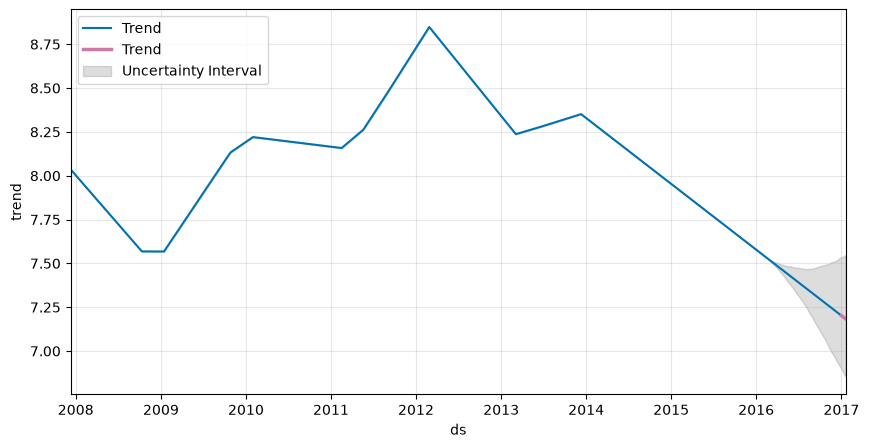

GAP on start periode (2008): 0.0
GAP on last periode (prediction) (2017): 0.6955914168218804


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from prophet.plot import plot_plotly,plot_components_plotly

df = pd.read_csv('https://raw.githubusercontent.com/facebook/prophet/main/examples/example_wp_log_peyton_manning.csv')
# print(df.isnull().sum())
m=Prophet()
m.fit(df)

future=m.make_future_dataframe(periods=365)
forecast=m.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()
# fig1=m.plot(forecast)
# fig2 = m.plot_components(forecast)

# print(forecast)
# print(forecast[["ds","yhat"]])
forecast['ds'] = pd.to_datetime(forecast['ds'])
is_above_2016 = forecast['ds'].dt.year > 2016
forecast_above = forecast[is_above_2016]
forecast_base = forecast[~is_above_2016]

plt.figure(figsize=(10, 5))
plt.plot(forecast_base['ds'], forecast_base['trend'], color='#0072B2', label='Trend')
plt.plot(forecast_above['ds'], forecast_above['trend'],linewidth=2.5, color='#CC79A7', label='Trend')
plt.fill_between(
    forecast['ds'], 
    forecast['trend_lower'], 
    forecast['trend_upper'], 
    color='#555555', 
    alpha=0.2, 
    label='Uncertainty Interval'
)
plt.xlabel('ds')
plt.ylabel('trend')
plt.grid(False, linestyle='-', alpha=0.3)
plt.xlim(forecast['ds'].min(), forecast['ds'].max())
plt.legend(loc='upper left')
plt.show()

# Calculating the difference between the upper trend and the lower trend. to prove thats why gray area are visible.
forecast['trendGap'] = forecast['trend_upper'] - forecast['trend_lower']
# First data (head) VS end data (tail)
print("GAP on start periode (2008):", forecast['trendGap'].head(1).values[0])
print("GAP on last periode (prediction) (2017):", forecast['trendGap'].tail(1).values[0])

# Actual VS Prediction

Membandingkan 2 data antara aktual dengan kemungkinan atau prediksi dari 1 dataset 

15:30:20 - cmdstanpy - INFO - Chain [1] start processing


           ds      y
91 1967-08-01  13434
92 1967-09-01  13598
93 1967-10-01  17187
94 1967-11-01  16119
95 1967-12-01  13713


15:30:20 - cmdstanpy - INFO - Chain [1] done processing


MAE: 1336.814


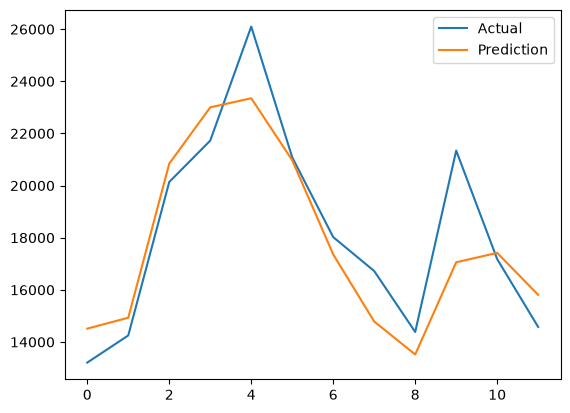

In [2]:
# evaluate prophet time series forecasting model on hold out dataset
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# load data
df = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv', header=0)

# prepare expected column names
df.columns = ['ds', 'y']
df['ds']= pd.to_datetime(df['ds'])

# create test dataset, remove last 12 months
train = df.drop(df.index[-12:])
print(train.tail())

model = Prophet()
model.fit(train)

# define the period for which we want a prediction
future = list()
for i in range(1, 13):
    date = '1968-%02d' % i
    future.append([date])
future = pd.DataFrame(future)
future.columns = ['ds']
future['ds'] = pd.to_datetime(future['ds'])

forecast = model.predict(future)
# calculate MAE between expected and predicted values for december
y_true = df['y'][-12:].values
y_pred = forecast['yhat'].values
mae = mean_absolute_error(y_true, y_pred)
print('MAE: %.3f' % mae)

# plot expected vs actual
plt.plot(y_true, label='Actual')
plt.plot(y_pred, label='Prediction')
plt.legend()
plt.show()

# Cross Validation

In [12]:
from prophet.diagnostics import cross_validation, performance_metrics
import pandas as pd
from prophet import Prophet
import openpyxl

df=pd.read_csv("../real_world_sales_dataset_5000.csv", header=0)
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%d-%m-%y")
dfA=df.groupby(pd.Grouper(key="Order_Date", freq="MS"))["Profit"].sum().reset_index()
dfA=dfA.rename(columns={"Order_Date": "ds", "Profit": "y"})
m=Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
m.fit(dfA)
df_cv=cross_validation(m, initial='730 days', period='180 days', horizon='10 days')
print(df_cv)
df_p=performance_metrics(df_cv)
print(df_p[['horizon', 'mae', 'rmse', 'mape']].head())

15:44:28 - cmdstanpy - INFO - Chain [1] start processing
15:44:28 - cmdstanpy - INFO - Chain [1] done processing


  0%|          | 0/1 [00:00<?, ?it/s]

15:44:28 - cmdstanpy - INFO - Chain [1] start processing
15:44:28 - cmdstanpy - INFO - Chain [1] done processing


          ds           yhat     yhat_lower     yhat_upper         y     cutoff
0 2025-06-01  223149.874919  211743.269171  233681.765111  130538.6 2025-05-22
  horizon           mae          rmse      mape
0 10 days  92611.274919  92611.274919  0.709455


In [27]:
from prophet.diagnostics import cross_validation

df_cv = cross_validation(m, initial='730 days', period='180 days', horizon = '150 days')
df_cv.head()


## Deskripsi
**1. initial ('730 days')**
- Apa itu: Ukuran atau durasi data historis pertama yang digunakan untuk pelatihan model (training) pada fold atau iterasi pertama.
- Cara kerjanya: Model Prophet pertama kali akan dilatih menggunakan data selama 730 hari (sekitar 2 tahun) pertama dari dataset Anda.

**2. period ('180 days')**
- Apa itu: Jarak atau interval waktu antara tanggal cutoff (titik potong evaluasi) satu dengan berikutnya.
- Cara kerjanya: Setelah iterasi pertama selesai, tanggal cutoff akan digeser maju sebanyak 180 hari (sekitar 6 bulan) untuk melakukan evaluasi/pelatihan ulang berikutnya.

**3. horizon ('150 days')**
- Apa itu: Durasi atau seberapa jauh ke depan waktu yang ingin diramalkan (forecasting) oleh model.
- Cara kerjanya: Dari setiap tanggal cutoff, model akan mencoba memprediksi nilai untuk 150 hari ke depan, lalu hasilnya dibandingkan dengan data asli yang sebenarnya (ground truth).